# SECOM DL 실험 (MLP · 오토인코더)

## 0. 데이터 로딩 + 공통 평가 도구
README 6번 코드로 데이터를 불러오고, `src/secom_eval.py`에서 공통 도구(`MissingFlagger`, `impute_steps`, `score`, `evaluate`, cv/inner_cv, 시간순 분할)를 import한다.
- `DEV=True`로 고정한다 (10-fold × 1).
- **규칙**: 모든 실험은 `evaluate()`로 같은 fold에서 평가한다. 판단은 CV BER과 PR-AUC로 하고, 시간순 결과는 출력만 한다.
- 실험마다 `EXP[이름]`에 가설과 변경을 기록해 두고, 마지막 셀에서 실험 로그 표로 모은다.

In [12]:
import sys
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pyprojroot import here

sys.path.insert(0, str(here()))   # 프로젝트 루트 → `src` 패키지 import 가능
from src.secom_eval import SecomEval, MissingFlagger, impute_steps, score, unwrap, timed

from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # max_iter 고정 실험이라 미수렴 경고는 숨김

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

with timed("데이터 로딩"):
    DATA_DIR = here("data/raw")

    # 피처
    X = pd.read_csv(DATA_DIR / "secom.data", sep=r"\s+", header=None)
    X.columns = [f"f{i}" for i in range(X.shape[1])]

    # 라벨 + 타임스탬프
    y = pd.read_csv(DATA_DIR / "secom_labels.data", sep=" ", header=None,
                    names=["label", "timestamp"], quotechar='"')
    y["timestamp"] = pd.to_datetime(y["timestamp"], format="%d/%m/%Y %H:%M:%S")

    # 합치기
    df = pd.concat([y, X], axis=1)
    print(df.shape)                    # (1567, 592)
    print(df["label"].value_counts())

    # 분석용 이진 라벨: 1 = Fail, 0 = Pass
    yb = (y["label"] == 1).astype(int)

    # 모델링 입력: EDA에서 고른 대표 변수 282개 (X2)
    rep = pd.read_csv(here("data/processed/rep_features.csv"))["feature"].tolist()
    X2 = X[rep]
    print(X2.shape)                    # (1567, 282)

    DEV = True   # 이 노트북은 DEV 고정 (10-fold × 1)
    ev = SecomEval(X2, yb, y["timestamp"], dev=DEV)
    evaluate = ev.evaluate
    cv, inner_cv = ev.cv, ev.inner_cv
    ev.summary()

EXP = {}   # 실험 로그: {results 이름: {"실험", "가설", "변경"}}

[시작] 데이터 로딩 19:43:32
(1567, 592)
label
-1    1463
 1     104
Name: count, dtype: int64
(1567, 282)
DEV=True, outer folds = 10
시간순: 학습 1253 (불량 87) / 테스트 314 (불량 17)
[끝] 데이터 로딩 19:43:32 (소요 0.3s)


## M1. MLP: early stopping 끄기
`impute_steps()` → StandardScaler → MLPClassifier((64,), `alpha=1e-3`, `early_stopping=False`, `max_iter=200`), `tune_threshold=True`
- 가설: early stopping은 학습 데이터의 10%를 검증용으로 떼어내는데, 그 안에 불량이 몇 개 안 된다. 그래서 너무 일찍 멈춰 학습이 부족했을 수 있다.
- 시간순 학습 모델의 `loss_curve_`를 그려서 200 epoch 동안 손실이 어떻게 줄어드는지 본다.

[시작] M1 19:43:46
[M1: MLP (64) no-ES]  (10 folds)
  CV    : BER 34.3±6.3 | recall 52.0±12.4 | PR_AUC 0.193±0.072 | F1 23.7±6.0
  시간순: BER 40.8 | recall 29.4 | PR_AUC 0.242 | F1 18.2
  사용 변수 수(fold 평균): 284.9
  임계값 fold별: [0.01, 0.01, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]
  임계값 평균 0.011±0.003 | 시간순 0.010


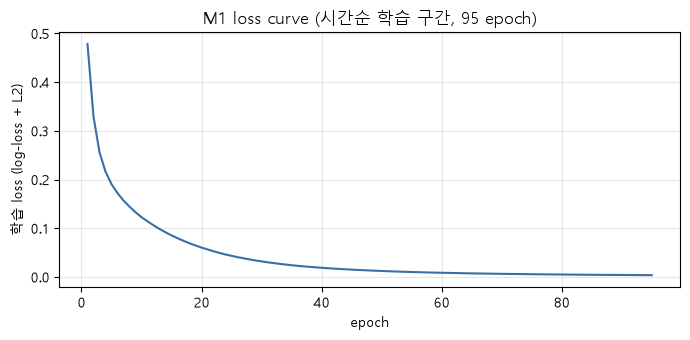

[끝] M1 19:45:27 (소요 101.1s)


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler


def mlp(**kw):
    p = dict(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=False, max_iter=200, random_state=42)
    p.update(kw)
    return MLPClassifier(**p)


with timed("M1"):
    name = "M1: MLP (64) no-ES"
    EXP[name] = {"실험": "M1", "가설": "early stopping이 너무 일찍 멈춰 학습 부족",
                 "변경": "early_stopping=False, max_iter=200, (64,), alpha=1e-3"}
    m1_pipe = Pipeline([*impute_steps(), ("scale", StandardScaler()), ("clf", mlp())])
    m1_folds, m1_time = evaluate(m1_pipe, name, tune_threshold=True)

    loss = m1_time.estimator_[-1].loss_curve_      # 임계값 래퍼 안의 Pipeline → MLP
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(np.arange(1, len(loss) + 1), loss, color="#3B6EA5")
    ax.set_xlabel("epoch")
    ax.set_ylabel("학습 loss (log-loss + L2)")
    ax.set_title(f"M1 loss curve (시간순 학습 구간, {len(loss)} epoch)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## M2. MLP + RandomOverSampler
M1 구조에서 분류기 바로 앞에 `RandomOverSampler(random_state=42)`를 넣는다 (imblearn Pipeline).
- 오버샘플링은 학습 fold에서만 일어나고, 테스트 fold와 임계값을 정하는 내부 검증 분할에는 적용되지 않는다.
- 가설: MLP는 class_weight 옵션이 없다. 불량을 복제해 학습 데이터의 균형을 맞추면 불량 쪽 경계를 더 잘 배울 수 있다.

In [14]:
def m2_pipe(**kw):
    return ImbPipeline([
        *impute_steps(),
        ("scale", StandardScaler()),
        ("ros", RandomOverSampler(random_state=42)),   # 학습 fold에서만
        ("clf", mlp(**kw)),
    ])


with timed("M2"):
    name = "M2: MLP (64) + ROS"
    EXP[name] = {"실험": "M2", "가설": "학습 fold 불량을 복제해 균형 맞추면 불량 경계 학습↑",
                 "변경": "M1 + RandomOverSampler(분류기 앞)"}
    m2_folds, m2_time = evaluate(m2_pipe(), name, tune_threshold=True)

[시작] M2 19:45:27
[M2: MLP (64) + ROS]  (10 folds)
  CV    : BER 35.4±6.3 | recall 50.8±12.9 | PR_AUC 0.178±0.062 | F1 22.4±5.6
  시간순: BER 36.4 | recall 35.3 | PR_AUC 0.225 | F1 25.5
  사용 변수 수(fold 평균): 284.9
  임계값 fold별: [0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]
  임계값 평균 0.011±0.003 | 시간순 0.020
[끝] M2 19:47:19 (소요 112.3s)


## M3. MLP alpha 튜닝 (규제 강화)
M1 구조를 그대로 쓴다: `impute_steps()` → StandardScaler → MLPClassifier((64,), `early_stopping=False`, `max_iter=200`), RandomOverSampler 없음.
여기에 GridSearchCV(`inner_cv`, balanced_accuracy)로 `alpha` [1e-2, 1e-1, 1, 10]을 고르고, 그 바깥에서 임계값 튜닝을 한다.
- 가설: M1은 학습 데이터를 외웠다(학습 loss ≈ 0.005, 임계값 ≈ 0.01). L2 규제를 강하게 하면 일반화가 좋아진다.
- fold별 best alpha와 시간순 학습 모델의 `loss_curve_`를 출력한다. loss가 0 근처까지 떨어지지 않는지 M1 곡선과 비교한다.
- 비용: outer fold마다 GridSearch 6번 × 20 fit이다. 전체로 MLP를 약 1,300번 학습한다.

[시작] M3 18:45:31
[M3: MLP alpha 튜닝]  (10 folds)
  CV    : BER 35.8±8.2 | recall 58.8±14.0 | PR_AUC 0.173±0.052 | F1 21.6±6.0
  시간순: BER 40.1 | recall 23.5 | PR_AUC 0.241 | F1 25.0
  사용 변수 수(fold 평균): 284.9
  임계값 fold별: [0.02, 0.04, 0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]
  임계값 평균 0.016±0.009 | 시간순 0.040
fold별 best alpha: [0.01, 1, 1, 0.1, 0.01, 0.01, 0.01, 1, 0.01, 0.01]
best alpha 빈도: {0.01: 6, 0.1: 1, 1.0: 3}
시간순 학습 모델 best alpha: 0.01


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


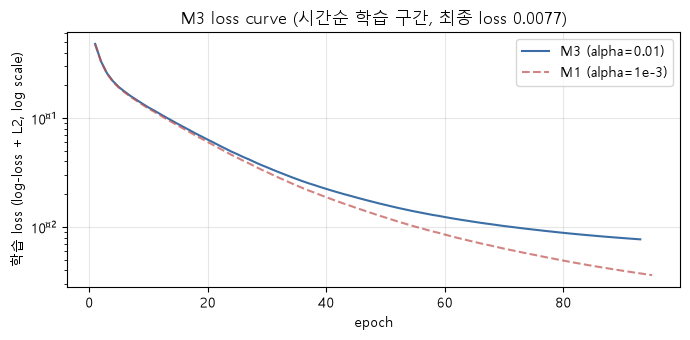

[끝] M3 19:00:08 (소요 877.0s)


In [ ]:
with timed("M3"):
    name = "M3: MLP alpha 튜닝"
    EXP[name] = {"실험": "M3",
                 "가설": "M1이 학습 데이터를 외움(loss≈0, 임계값 0.01) → 규제 강화로 일반화 개선",
                 "변경": "M1 + GridSearch alpha [1e-2, 1e-1, 1, 10] (hidden (64,) 고정, ROS 없음)"}
    m3_pipe = Pipeline([*impute_steps(), ("scale", StandardScaler()), ("clf", mlp())])   # M1과 같은 구조
    m3_gs = GridSearchCV(m3_pipe, {"clf__alpha": [1e-2, 1e-1, 1, 10]},
                         scoring="balanced_accuracy", cv=inner_cv, n_jobs=-1)
    m3_folds, m3_time = evaluate(m3_gs, name, tune_threshold=True)

    best_alpha = [m.estimator_.best_params_["clf__alpha"] for m in m3_folds]   # 래퍼 → GridSearchCV
    print("fold별 best alpha:", best_alpha)
    print("best alpha 빈도:", pd.Series(best_alpha).value_counts().sort_index().to_dict())
    t_alpha = m3_time.estimator_.best_params_["clf__alpha"]
    print("시간순 학습 모델 best alpha:", t_alpha)

    loss3 = unwrap(m3_time)[-1].loss_curve_            # 래퍼 → GridSearch best Pipeline → MLP
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(np.arange(1, len(loss3) + 1), loss3, color="#3B6EA5", label=f"M3 (alpha={t_alpha:g})")
    if "m1_time" in globals():                         # M1을 실행했으면 비교용으로 같이 그림
        loss1 = m1_time.estimator_[-1].loss_curve_
        ax.plot(np.arange(1, len(loss1) + 1), loss1, color="#C0504D", ls="--", alpha=0.7, label="M1 (alpha=1e-3)")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("학습 loss (log-loss + L2, log scale)")
    ax.set_title(f"M3 loss curve (시간순 학습 구간, 최종 loss {loss3[-1]:.4f})")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
plt.rcParams['axes.unicode_minus'] = False

## AEDetector: 오토인코더 이상탐지 분류기
sklearn `MLPRegressor`로 X → X를 복원하는 오토인코더를 분류기 인터페이스로 감싼다.
- `fit(X, y)`
  - 전처리(`impute_steps()` + 스케일러)는 학습 fold **전체**로 fit한다.
  - 오토인코더는 그중 **양품(y == 0)만**으로 학습한다.
- `decision_function(X)`: 샘플별 평균 제곱 복원 오차를 반환한다. 클수록 불량에 가깝다.
- `predict_proba(X)`: 오차 e를 학습 양품 오차의 중앙값 m으로 `e / (e + m)` 변환해 0~1로 만든다.
  - 순서가 그대로 보존되어 PR-AUC가 변하지 않는다.
  - 최대·최소로 자르는 min-max와 달리, 학습 때보다 큰 오차도 1에 몰리지 않는다.
  - `TunedThresholdClassifierCV`와 호환되며, 임계값은 학습 fold 안에서 정해진다.
- `feature_errors(X)`: 변수별 제곱 복원 오차 표. 어떤 센서가 튀었는지 볼 때 쓴다.

In [6]:
from sklearn.base import BaseEstimator, ClassifierMixin


class AEDetector(ClassifierMixin, BaseEstimator):
    """양품만으로 학습한 오토인코더의 복원 오차를 불량 점수로 쓰는 분류기"""

    def __init__(self, hidden=(64, 16, 64), scaler="standard", alpha=1e-4,
                 max_iter=300, early_stopping=True, random_state=42):
        self.hidden = hidden
        self.scaler = scaler
        self.alpha = alpha
        self.max_iter = max_iter
        self.early_stopping = early_stopping
        self.random_state = random_state

    def _make_prep(self, n):
        if self.scaler == "standard":
            sc = StandardScaler()
        elif self.scaler == "quantile":
            sc = QuantileTransformer(n_quantiles=min(1000, n), output_distribution="normal", random_state=0)
        else:
            raise ValueError(f"unknown scaler: {self.scaler}")
        return Pipeline([*impute_steps(), ("scale", sc)])

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        self.prep_ = self._make_prep(len(X)).fit(X)            # 학습 fold 전체로 전처리 fit
        Z = self.prep_.transform(X)
        Zg = Z[y == 0]                                          # 양품만으로 AE 학습
        self.ae_ = MLPRegressor(hidden_layer_sizes=self.hidden, alpha=self.alpha, max_iter=self.max_iter,
                                early_stopping=self.early_stopping, random_state=self.random_state).fit(Zg, Zg)
        self.ref_ = float(np.median(self._sq_err(Zg).mean(axis=1)))   # 학습 양품 오차 중앙값
        self.feature_names_out_ = self.prep_.get_feature_names_out()
        return self

    def _sq_err(self, Z):
        return (Z - self.ae_.predict(Z)) ** 2

    def decision_function(self, X):
        return self._sq_err(self.prep_.transform(X)).mean(axis=1)

    def predict_proba(self, X):
        e = self.decision_function(X)
        p = e / (e + self.ref_)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

    def feature_errors(self, X):
        """변수별 제곱 복원 오차 (행 = 샘플, 열 = 전처리 후 변수 이름)"""
        return pd.DataFrame(self._sq_err(self.prep_.transform(X)), columns=self.feature_names_out_,
                            index=getattr(X, "index", None))


ae_time = {}   # 실험 이름 → 시간순 학습 모델 (변수별 오차 분석용)

## A1. 오토인코더 기본
AEDetector(은닉 (64, 16, 64), StandardScaler), `tune_threshold=True`
- 가설: 양품만으로 학습한 AE는 불량을 잘 복원하지 못하므로, 복원 오차로 불량을 구별할 수 있다.

In [7]:
with timed("A1"):
    name = "A1: AE (64,16,64) std"
    EXP[name] = {"실험": "A1", "가설": "양품만 학습한 AE의 복원 오차로 불량 구별",
                 "변경": "AE (64,16,64), StandardScaler"}
    _, ae_time[name] = evaluate(AEDetector(hidden=(64, 16, 64), scaler="standard"), name, tune_threshold=True)

[시작] A1 19:32:10
[A1: AE (64,16,64) std]  (10 folds)
  CV    : BER 46.0±7.5 | recall 33.9±14.4 | PR_AUC 0.117±0.030 | F1 13.7±5.2
  시간순: BER 53.8 | recall 64.7 | PR_AUC 0.043 | F1 9.1
  사용 변수 수(fold 평균): 282.0
  임계값 fold별: [0.541, 0.556, 0.563, 0.536, 0.562, 0.571, 0.564, 0.535, 0.619, 0.554]
  임계값 평균 0.560±0.023 | 시간순 0.545
[끝] A1 19:32:50 (소요 40.4s)


## A2. 병목 크기 비교 (64, k, 64), k = 8 / 16 / 32
- 가설: 병목이 너무 작으면 양품도 잘 복원하지 못하고, 너무 크면 불량까지 복원해 버린다. 둘 다 구별력이 떨어진다.
- k = 16은 A1과 설정이 같아서 다시 돌리지 않고 A1 결과를 쓴다.
- 가장 좋은 k는 CV BER이 가장 낮은 것으로 고르고, 같으면 CV PR-AUC가 높은 쪽을 고른다.

In [8]:
with timed("A2"):
    a2_names = {16: "A1: AE (64,16,64) std"}
    for k in [8, 32]:
        name = f"A2: AE (64,{k},64) std"
        EXP[name] = {"실험": "A2", "가설": "병목 크기가 복원/구별 균형을 좌우",
                     "변경": f"A1에서 병목 16 → {k}"}
        _, ae_time[name] = evaluate(AEDetector(hidden=(64, k, 64), scaler="standard"), name, tune_threshold=True)
        a2_names[k] = name

    _res = pd.DataFrame(ev.results).set_index("model")
    a2 = pd.DataFrame({k: _res.loc[n, ["BER_mean", "PR_AUC_mean", "BER_time"]] for k, n in a2_names.items()}).T.sort_index()
    a2.index.name = "병목 k"
    display(a2.style.format({"BER_mean": "{:.1%}", "PR_AUC_mean": "{:.3f}", "BER_time": "{:.1%}"}))
    best_k = a2.sort_values(["BER_mean", "PR_AUC_mean"], ascending=[True, False]).index[0]
    print("best 병목 k =", best_k)

[시작] A2 19:33:44
[A2: AE (64,8,64) std]  (10 folds)
  CV    : BER 45.4±9.0 | recall 34.0±17.5 | PR_AUC 0.117±0.029 | F1 14.1±6.4
  시간순: BER 55.5 | recall 64.7 | PR_AUC 0.044 | F1 8.7
  사용 변수 수(fold 평균): 282.0
  임계값 fold별: [0.545, 0.551, 0.564, 0.537, 0.635, 0.568, 0.557, 0.542, 0.548, 0.62]
  임계값 평균 0.567±0.032 | 시간순 0.537
[A2: AE (64,32,64) std]  (10 folds)
  CV    : BER 45.3±7.8 | recall 33.9±15.4 | PR_AUC 0.116±0.030 | F1 14.0±5.4
  시간순: BER 54.7 | recall 64.7 | PR_AUC 0.043 | F1 8.9
  사용 변수 수(fold 평균): 282.0
  임계값 fold별: [0.553, 0.558, 0.571, 0.537, 0.57, 0.567, 0.564, 0.563, 0.555, 0.618]
  임계값 평균 0.565±0.020 | 시간순 0.543


,BER_mean,PR_AUC_mean,BER_time
병목 k,,,
8,45.4%,0.117,55.5%
16,46.0%,0.117,53.8%
32,45.3%,0.116,54.7%


best 병목 k = 32
[끝] A2 19:35:13 (소요 89.7s)


## A3. best 병목 + QuantileTransformer(normal)
A2에서 고른 병목에 StandardScaler 대신 `QuantileTransformer(output_distribution="normal")`를 쓴다.
- 가설: 이상치가 큰 센서는 복원 오차를 지배한다. 분위수 변환으로 이상치 영향을 줄이면 오차 점수가 덜 흔들린다.

In [9]:
with timed("A3"):
    name = f"A3: AE (64,{best_k},64) quantile"
    EXP[name] = {"실험": "A3", "가설": "분위수 변환으로 이상치 영향↓ → 오차 점수 안정",
                 "변경": f"병목 {best_k} + QuantileTransformer(normal)"}
    _, ae_time[name] = evaluate(AEDetector(hidden=(64, best_k, 64), scaler="quantile"), name, tune_threshold=True)

[시작] A3 19:35:56
[A3: AE (64,32,64) quantile]  (10 folds)
  CV    : BER 42.2±7.3 | recall 43.8±17.4 | PR_AUC 0.125±0.034 | F1 16.2±6.3
  시간순: BER 54.8 | recall 52.9 | PR_AUC 0.041 | F1 8.5
  사용 변수 수(fold 평균): 282.0
  임계값 fold별: [0.54, 0.544, 0.554, 0.561, 0.554, 0.556, 0.558, 0.555, 0.566, 0.538]
  임계값 평균 0.553±0.009 | 시간순 0.605
[끝] A3 19:38:58 (소요 181.5s)


## AE 변수별 복원 오차 (어떤 센서가 튀었나)
AE 실험(A1~A3) 중 CV BER이 가장 낮은 모델(같으면 PR-AUC가 높은 쪽)을 고른다. 그 모델의 시간순 학습 모델로 **시간순 테스트 구간의 불량 샘플**에서 변수별 평균 복원 오차를 구하고 상위 15개를 출력한다.
- 같은 구간 양품의 평균 오차와 그 비율도 함께 보여준다.
- `fX_na`는 결측 플래그다.

In [10]:
with timed("AE 변수별 오차"):
    _res = pd.DataFrame(ev.results).set_index("model").loc[list(ae_time)]
    best_ae = _res.sort_values(["BER_mean", "PR_AUC_mean"], ascending=[True, False]).index[0]
    print(f"best AE: {best_ae}  (CV BER {_res.loc[best_ae, 'BER_mean']*100:.1f}%, PR-AUC {_res.loc[best_ae, 'PR_AUC_mean']:.3f})")

    det = unwrap(ae_time[best_ae])                      # TunedThresholdClassifierCV → AEDetector
    fail = ev.y_te_t == 1
    err_fail = det.feature_errors(ev.X_te_t[fail]).mean()
    err_pass = det.feature_errors(ev.X_te_t[~fail]).mean()
    top = pd.DataFrame({"불량 평균 오차": err_fail, "양품 평균 오차": err_pass,
                        "비율 (불량/양품)": err_fail / err_pass}).sort_values("불량 평균 오차", ascending=False).head(15)
    print(f"시간순 테스트: 불량 {fail.sum()}개 / 양품 {(~fail).sum()}개")
    display(top.style.format("{:.3f}").set_caption(f"{best_ae}: 불량 샘플 변수별 평균 복원 오차 상위 15"))

[시작] AE 변수별 오차 19:40:13
best AE: A3: AE (64,32,64) quantile  (CV BER 42.2%, PR-AUC 0.125)
시간순 테스트: 불량 17개 / 양품 297개


,불량 평균 오차,양품 평균 오차,비율 (불량/양품)
f132,5.270,1.160,4.543
f109,4.645,12.335,0.377
f111,4.456,13.589,0.328
f6,4.311,6.972,0.618
f129,3.957,1.654,2.393
f110,3.769,10.021,0.376
f485,3.731,4.834,0.772
f134,3.090,2.249,1.374
f164,2.855,1.186,2.407
f244,2.845,1.954,1.456


[끝] AE 변수별 오차 19:40:13 (소요 0.4s)


## 실험 로그
실험 | 가설 | 변경 | CV BER | CV PR-AUC | 시간순 BER | 판단(빈칸). **판단**은 CV BER과 PR-AUC를 보고 직접 채운다.

In [11]:
_r = pd.DataFrame(ev.results)
_r = _r[_r["model"].isin(EXP)]
log = pd.DataFrame({
    "실험": [EXP[n]["실험"] for n in _r["model"]],
    "이름": _r["model"].values,
    "가설": [EXP[n]["가설"] for n in _r["model"]],
    "변경": [EXP[n]["변경"] for n in _r["model"]],
    "CV BER (%)": [f"{m*100:.1f} ± {s*100:.1f}" for m, s in zip(_r["BER_mean"], _r["BER_std"])],
    "CV PR-AUC": [f"{m:.3f} ± {s:.3f}" for m, s in zip(_r["PR_AUC_mean"], _r["PR_AUC_std"])],
    "시간순 BER (%)": (_r["BER_time"] * 100).round(1).values,
    "판단": "",
})
with pd.option_context("display.max_colwidth", None):
    display(log.style.hide(axis="index").set_properties(**{"text-align": "left"}))

실험,이름,가설,변경,CV BER (%),CV PR-AUC,시간순 BER (%),판단
M1,M1: MLP (64) no-ES,early stopping이 너무 일찍 멈춰 학습 부족,"early_stopping=False, max_iter=200, (64,), alpha=1e-3",34.3 ± 6.3,0.193 ± 0.072,40.800000,
M2,M2: MLP (64) + ROS,학습 fold 불량을 복제해 균형 맞추면 불량 경계 학습↑,M1 + RandomOverSampler(분류기 앞),35.4 ± 6.3,0.178 ± 0.062,36.400000,
M3,M3: MLP alpha 튜닝,"M1이 학습 데이터를 외움(loss≈0, 임계값 0.01) → 규제 강화로 일반화 개선","M1 + GridSearch alpha [1e-2, 1e-1, 1, 10] (hidden (64,) 고정, ROS 없음)",35.8 ± 8.2,0.173 ± 0.052,40.100000,
A1,"A1: AE (64,16,64) std",양품만 학습한 AE의 복원 오차로 불량 구별,"AE (64,16,64), StandardScaler",46.0 ± 7.5,0.117 ± 0.030,53.800000,
A2,"A2: AE (64,8,64) std",병목 크기가 복원/구별 균형을 좌우,A1에서 병목 16 → 8,45.4 ± 9.0,0.117 ± 0.029,55.500000,
A2,"A2: AE (64,32,64) std",병목 크기가 복원/구별 균형을 좌우,A1에서 병목 16 → 32,45.3 ± 7.8,0.116 ± 0.030,54.700000,
A3,"A3: AE (64,32,64) quantile",분위수 변환으로 이상치 영향↓ → 오차 점수 안정,병목 32 + QuantileTransformer(normal),42.2 ± 7.3,0.125 ± 0.034,54.800000,


### 실험 판단

| 실험 | 결과 | 판단 |
|---|---|---|
| **M1** early stopping 끄기 | BER 39.9 → **34.3** | ✅ **가설 지지.** 정확도 기준 early stopping이 불균형 데이터에서 조기 종료시켰음. 다만 학습 loss ≈ 0, 임계값 0.01 → 학습 데이터를 외우는 과적합 신호 |
| **M2** + 오버샘플링 | 34.3 → 35.4, PR-AUC 0.193 → 0.178 | ❌ **가설 기각.** 임계값이 여전히 0.01. 원인은 불량 노출 부족이 아니라 과적합이고, 같은 불량을 복제하면 암기만 강화됨 |
| **M3** alpha 튜닝 | 35.8, PR-AUC 0.173 | ❌ **가설 기각.** 대부분 fold가 가장 약한 규제(0.01)를 선택했고 loss도 여전히 0 근처. 단, alpha 선택 점수가 임계값 0.5 기준이라 확률이 낮은 MLP에선 비교가 부정확했을 수 있음 → PR-AUC 기준 재탐색은 추후 과제 |
| **A1** 오토인코더 | BER 46.0, PR-AUC 0.117 (무작위 0.066) | △ **약하게 지지.** 불량이 덜 복원되는 신호는 있지만 분류 모델보다 크게 열세. 라벨 없이 282개 센서를 똑같이 다뤄서 불량과 무관한 변동에 신호가 묻힘 |
| **A2** 병목 8 / 32 | 45.3~46.0, PR-AUC 0.116~0.117 | ❌ **차이 없음.** 성능을 제한하는 건 모델 용량이 아니라 입력 신호 |
| **A3** Quantile 변환 | BER 42.2, PR-AUC 0.125, recall 34 → 44 | △ **부분 지지.** 이상치가 복원 오차를 일부 왜곡하고 있었음. 하지만 분류 모델(PR-AUC 0.19~0.25)과는 여전히 큰 차이 |

**종합**
- MLP: early stopping 문제를 고쳐 39.9 → 34.3으로 기준선 수준까지 개선. 오버샘플링·규제 강화로는 더 오르지 않음 → 데이터 규모의 한계로 최상위 ML(LightGBM·EN)에는 못 미침
- 오토인코더: 비지도 '이상'과 '불량'은 다름. 불량에서 튀는 센서(f132, f75, f25, f129)는 분류 모델 핵심(f59, f21)과 거의 겹치지 않음
- **드리프트 증거**: f109~f111, f6, f485는 테스트 구간 **양품**의 복원 오차가 불량보다 큼 → 시간순 성능 하락이 센서 분포 변화 때문이라는 가설을 직접 뒷받침 (결측 65% 그룹 포함이라 해석 주의)
- 판단은 CV 기준, 시간순은 참고로만 기록